In [1]:
import pandas as pd

prices = pd.read_excel("Historical Data Apple.xlsx")

prices.head()

,Date,Close,High,Low,Open,Adj Close,Volume,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11
0,2020-01-02,75.087502,75.150002,73.797501,74.059998,72.216675,135480400,NaN,NaN,NaN,NaN,NaN
1,2020-01-03,74.357498,75.144997,74.125000,74.287498,71.514595,146322800,NaN,NaN,NaN,NaN,NaN
2,2020-01-06,74.949997,74.989998,73.187500,73.447502,72.084412,118387200,NaN,NaN,NaN,NaN,NaN
3,2020-01-07,74.597504,75.224998,74.370003,74.959999,71.745445,108872000,NaN,NaN,NaN,NaN,NaN
4,2020-01-08,75.797501,76.110001,74.290001,74.290001,72.899536,132079200,NaN,NaN,NaN,NaN,\


In [2]:
prices = pd.read_excel(
    "Historical Data Apple.xlsx",
    usecols="A:G"
)

prices.head()

,Date,Close,High,Low,Open,Adj Close,Volume
0,2020-01-02,75.087502,75.150002,73.797501,74.059998,72.216675,135480400
1,2020-01-03,74.357498,75.144997,74.125000,74.287498,71.514595,146322800
2,2020-01-06,74.949997,74.989998,73.187500,73.447502,72.084412,118387200
3,2020-01-07,74.597504,75.224998,74.370003,74.959999,71.745445,108872000
4,2020-01-08,75.797501,76.110001,74.290001,74.290001,72.899536,132079200


In [3]:
prices.info()

<class 'pandas.DataFrame'>
RangeIndex: 1729 entries, 0 to 1728
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       1729 non-null   datetime64[us]
 1   Close      1729 non-null   float64       
 2   High       1729 non-null   float64       
 3   Low        1729 non-null   float64       
 4   Open       1729 non-null   float64       
 5   Adj Close  1729 non-null   float64       
 6   Volume     1729 non-null   int64         
dtypes: datetime64[us](1), float64(5), int64(1)
memory usage: 94.7 KB


In [4]:
print("Missing values by column:")
print(prices.isna().sum())

print("Duplicate rows:", prices.duplicated().sum())

Missing values by column:
Date         0
Close        0
High         0
Low          0
Open         0
Adj Close    0
Volume       0
dtype: int64
Duplicate rows: 0


In [5]:
if "Adj Close" in prices.columns:
    price_column = "Adj Close"
else:
    price_column = "Close"

prices["Daily Return"] = prices[price_column].pct_change()

prices[["Date", price_column, "Daily Return"]].head()

,Date,Adj Close,Daily Return
0,2020-01-02,72.216675,NaN
1,2020-01-03,71.514595,-0.009722
2,2020-01-06,72.084412,0.007968
3,2020-01-07,71.745445,-0.004702
4,2020-01-08,72.899536,0.016086


In [6]:
prices["Daily Return Percent"] = prices["Daily Return"] * 100

prices[["Date", "Daily Return Percent"]].head()

,Date,Daily Return Percent
0,2020-01-02,NaN
1,2020-01-03,-0.972185
2,2020-01-06,0.796784
3,2020-01-07,-0.470235
4,2020-01-08,1.608591


In [7]:
average_daily_return = prices["Daily Return"].mean()
daily_volatility = prices["Daily Return"].std()

annualized_volatility = daily_volatility * (252 ** 0.5)

print("Average daily return:", round(average_daily_return * 100, 3), "%")
print("Annualized volatility:", round(annualized_volatility * 100, 2), "%")

Average daily return: 0.111 %
Annualized volatility: 31.13 %


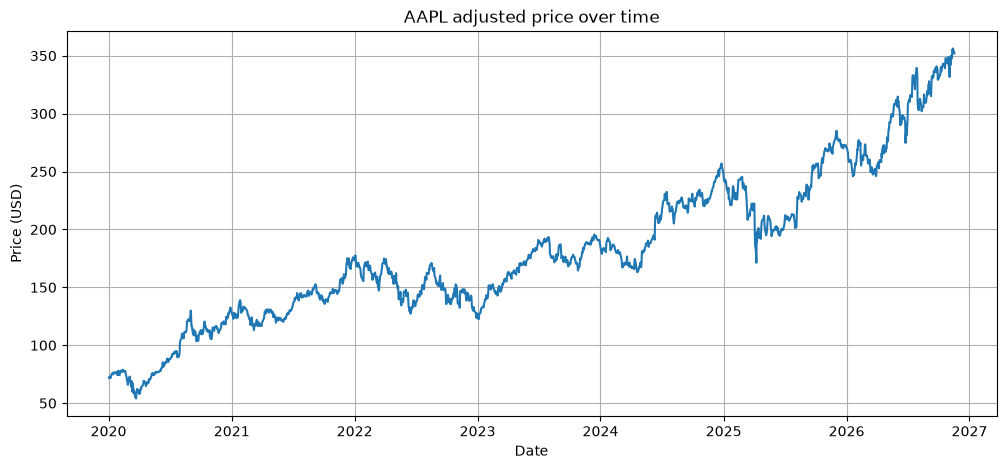

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(prices["Date"], prices[price_column])
plt.title("AAPL adjusted price over time")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.grid(True)
plt.show()

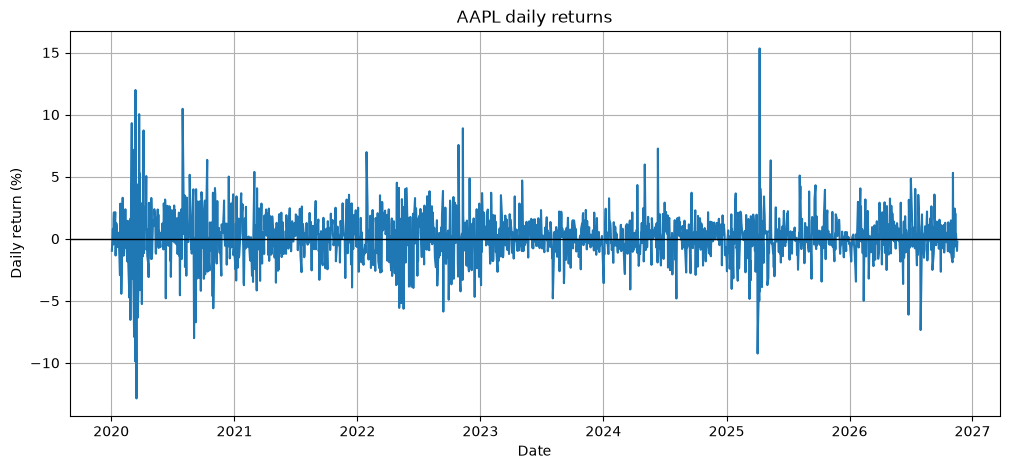

In [9]:
plt.figure(figsize=(12, 5))
plt.plot(prices["Date"], prices["Daily Return"] * 100)
plt.title("AAPL daily returns")
plt.xlabel("Date")
plt.ylabel("Daily return (%)")
plt.axhline(0, color="black", linewidth=1)
plt.grid(True)
plt.show()

In [10]:
best_day = prices.loc[prices["Daily Return"].idxmax()]
worst_day = prices.loc[prices["Daily Return"].idxmin()]

print("Data period:", prices["Date"].min().date(), "to", prices["Date"].max().date())
print("Largest increase:", best_day["Date"].date(),
      round(best_day["Daily Return"] * 100, 2), "%")
print("Largest decrease:", worst_day["Date"].date(),
      round(worst_day["Daily Return"] * 100, 2), "%")

Data period: 2020-01-02 to 2026-11-17
Largest increase: 2025-04-09 15.33 %
Largest decrease: 2020-03-16 -12.86 %


In [11]:
prices.loc[
    prices["Date"].isin(pd.to_datetime(["2025-04-09", "2020-03-16"])),
    ["Date", "Open", "High", "Low", "Close", "Adj Close", "Volume", "Daily Return"]
]

,Date,Open,High,Low,Close,Adj Close,Volume,Daily Return
50,2020-03-16,60.487499,64.769997,60.000000,60.552502,58.375618,322423600,-0.128647
1324,2025-04-09,171.949997,200.610001,171.889999,198.850006,197.484344,184395900,0.153289
